In [21]:

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
import random
     

In [22]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [23]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()
     

(100, 6)


,col1,col2,col3,col4,col5,target
0,2.690442,-0.583555,0.539743,3.270832,4.519237,0
1,1.835304,-0.448987,-0.954713,0.526425,-1.230632,1
2,2.452721,0.866500,2.049160,2.028657,1.621107,0
3,-0.625744,2.912036,-3.236838,2.159794,-0.498958,1
4,0.079799,1.036720,1.907090,-0.483113,0.072051,0


In [24]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [25]:

# function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
  new_df = df[cols].copy()
  new_df.loc[:, 'target'] = df['target']
  return new_df


In [26]:
# function for combined sampling

def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [28]:
df1 = combined_sampling(df,0.5,0.5)
df1

,col2,col5,target
88,2.455447,3.207990,1
34,1.222738,0.794167,0
79,-0.961770,-0.614503,1
1,-0.448987,-1.230632,1
23,1.932871,-0.314950,1
73,2.302159,0.903642,0
37,0.743018,0.237938,0
21,0.340715,1.356613,0
25,2.993404,-2.283779,1
42,-0.473056,4.941215,0


In [30]:
df2 = combined_sampling(df,0.5,0.5)
df2

,col2,col3,target
49,-0.391236,2.140448,1
83,1.477033,-1.415372,1
39,0.907237,1.132876,0
38,3.085241,-1.425714,1
22,-1.746742,0.356545,1
95,0.917686,2.779627,0
51,1.530934,-2.843483,1
46,2.595419,-2.318514,1
62,0.674944,-1.687086,1
96,-0.188630,1.727198,0


In [31]:
df3 = combined_sampling(df,0.5,0.5)


In [32]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [33]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])
     

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [34]:
from sklearn.tree import plot_tree

[Text(0.5, 0.95, 'x[1] <= 0.641\ngini = 0.493\nsamples = 50\nvalue = [28.0, 22.0]'),
 Text(0.25, 0.85, 'x[0] <= -0.278\ngini = 0.417\nsamples = 27\nvalue = [8, 19]'),
 Text(0.375, 0.8999999999999999, 'True  '),
 Text(0.125, 0.75, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]'),
 Text(0.375, 0.75, 'x[0] <= 1.04\ngini = 0.472\nsamples = 21\nvalue = [8, 13]'),
 Text(0.25, 0.65, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.65, 'x[1] <= -2.305\ngini = 0.401\nsamples = 18\nvalue = [5, 13]'),
 Text(0.375, 0.55, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.625, 0.55, 'x[0] <= 2.698\ngini = 0.36\nsamples = 17\nvalue = [4, 13]'),
 Text(0.5, 0.45, 'x[0] <= 2.632\ngini = 0.444\nsamples = 12\nvalue = [4, 8]'),
 Text(0.375, 0.35, 'x[1] <= -0.327\ngini = 0.32\nsamples = 10\nvalue = [2, 8]'),
 Text(0.25, 0.25, 'x[1] <= -1.111\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.125, 0.15, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.375, 0.15, 'x[0] <= 1.494\ngini = 0.444\nsamples 

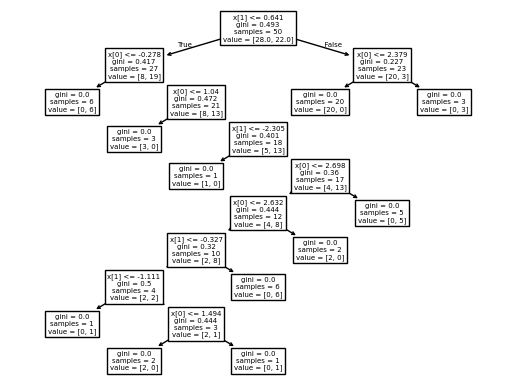

In [35]:
plot_tree(clf1)

[Text(0.4230769230769231, 0.95, 'x[1] <= -0.725\ngini = 0.499\nsamples = 50\nvalue = [24, 26]'),
 Text(0.34615384615384615, 0.85, 'gini = 0.0\nsamples = 14\nvalue = [0, 14]'),
 Text(0.3846153846153846, 0.8999999999999999, 'True  '),
 Text(0.5, 0.85, 'x[0] <= -0.288\ngini = 0.444\nsamples = 36\nvalue = [24, 12]'),
 Text(0.46153846153846156, 0.8999999999999999, '  False'),
 Text(0.3076923076923077, 0.75, 'x[1] <= 2.926\ngini = 0.375\nsamples = 8\nvalue = [2, 6]'),
 Text(0.23076923076923078, 0.65, 'x[1] <= 0.685\ngini = 0.245\nsamples = 7\nvalue = [1, 6]'),
 Text(0.15384615384615385, 0.55, 'x[1] <= 0.55\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.07692307692307693, 0.45, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.23076923076923078, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3076923076923077, 0.55, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.38461538461538464, 0.65, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.6923076923076923, 0.75, 'x[0] <

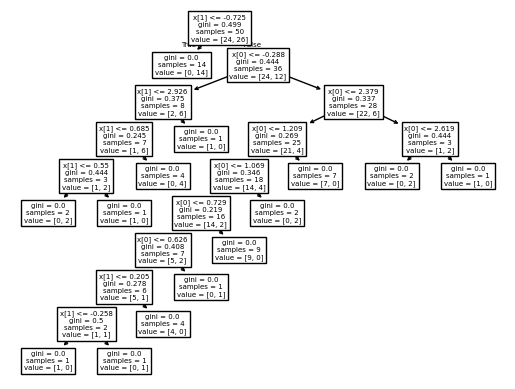

In [36]:
plot_tree(clf2)

[Text(0.42857142857142855, 0.9444444444444444, 'x[0] <= 2.431\ngini = 0.497\nsamples = 50\nvalue = [27, 23]'),
 Text(0.35714285714285715, 0.8333333333333334, 'x[1] <= -0.71\ngini = 0.498\nsamples = 43\nvalue = [20.0, 23.0]'),
 Text(0.39285714285714285, 0.8888888888888888, 'True  '),
 Text(0.2857142857142857, 0.7222222222222222, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.42857142857142855, 0.7222222222222222, 'x[0] <= 0.334\ngini = 0.484\nsamples = 39\nvalue = [16, 23]'),
 Text(0.2857142857142857, 0.6111111111111112, 'x[1] <= 1.601\ngini = 0.473\nsamples = 13\nvalue = [8, 5]'),
 Text(0.21428571428571427, 0.5, 'x[0] <= -0.123\ngini = 0.397\nsamples = 11\nvalue = [8, 3]'),
 Text(0.14285714285714285, 0.3888888888888889, 'x[1] <= 0.071\ngini = 0.5\nsamples = 6\nvalue = [3, 3]'),
 Text(0.07142857142857142, 0.2777777777777778, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.21428571428571427, 0.2777777777777778, 'x[0] <= -0.667\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(

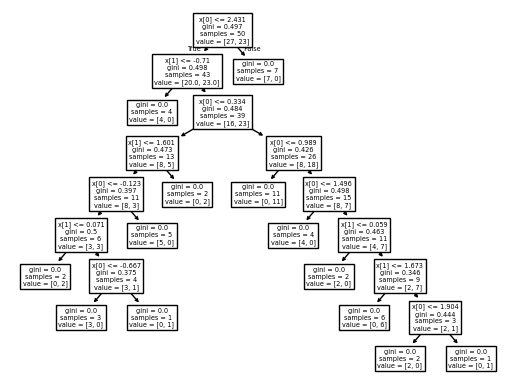

In [37]:
plot_tree(clf3)

In [38]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [39]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [40]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])